# 07 — Did the recording of incidents change in 2025?

**Goal.** From April 2025 the number of incidents a month falls by about 40%, while
incidents that delay service 5+ minutes stay level. Before the holdout (2024-01 to
2025-09) is rerun, decide what this means for it. The answer is fixed here, before any
new holdout result is seen.

Questions:
1. When does the drop start, and is it in every delay group or only the short ones?
2. Which incidents disappear?
3. Does the share of major incidents, which every ranking metric depends on, move
   outside its usual range?

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# The notebook lives in code/exploration/; the project modules live in code/.
sys.path.insert(0, str(Path.cwd().parent))
from cleaning.load import load_incidents
from modeling.target import add_targets, model_population

## 1. Monthly train incidents, by delay

Train incidents only (the model's population). "Short" is the 2-minutes-or-less and
3-4 minute buckets; "5+" is everything longer.

In [2]:
labelled = add_targets(model_population(load_incidents()))
month = labelled["service_date"].dt.to_period("M")
monthly = pd.DataFrame({
    "short (under 5 min)": (~labelled["y_5plus"]).groupby(month).sum(),
    "5+ min": labelled["y_5plus"].groupby(month).sum(),
    "major": labelled["y_major"].groupby(month).sum(),
})
monthly.tail(15)

,short (under 5 min),5+ min,major
service_date,,,
2024-07,307,85,28
2024-08,406,96,19
2024-09,395,138,19
2024-10,351,91,21
2024-11,290,72,21
2024-12,294,105,24
2025-01,403,110,28
2025-02,337,89,15
2025-03,328,109,20


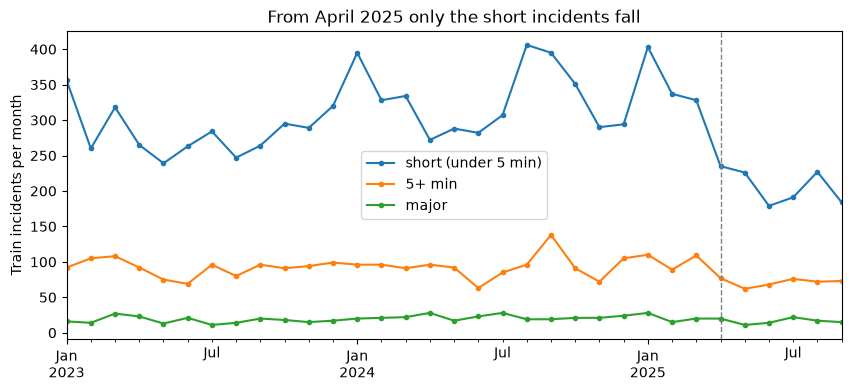

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
monthly.loc["2023-01":].plot(ax=ax, marker="o", markersize=3)
ax.axvline(pd.Period("2025-04", "M"), color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("Train incidents per month")
ax.set_xlabel("")
ax.set_title("From April 2025 only the short incidents fall")
plt.show()

## 2. Same months, every year

April-September of each year, so the comparison is not affected by season. The
question is whether 2025 is outside the range of 2019-2024 for the incidents that
matter (5+, safety, 30+, major) and for the share of major incidents.

In [4]:
april_to_september = labelled[labelled["service_date"].dt.month.between(4, 9)]
by_year = april_to_september.groupby(april_to_september["service_date"].dt.year)
same_months = pd.DataFrame({
    "incidents": by_year.size(),
    "short (under 5 min)": by_year["y_5plus"].apply(lambda flag: (~flag).sum()),
    "5+ min": by_year["y_5plus"].sum(),
    "safety": by_year["y_safety"].sum(),
    "30+ min": by_year["y_30plus"].sum(),
    "major": by_year["y_major"].sum(),
    "major share": by_year["y_major"].mean().round(3),
})
same_months

,incidents,short (under 5 min),5+ min,safety,30+ min,major,major share
service_date,,,,,,,
2019,2441,2011,430,109,28,117,0.048
2020,1585,1228,357,101,31,108,0.068
2021,1790,1382,408,123,35,131,0.073
2022,1973,1548,425,114,40,118,0.060
2023,2070,1562,508,97,32,102,0.049
2024,2520,1950,570,127,52,134,0.053
2025,1670,1242,428,94,35,99,0.059


## 3. Which incidents disappear?

April-September 2025 against the same months of 2024, by delay bucket and by primary
cause. The cause is recorded after the incident, so it is never a model input, but it
can describe what went missing.

In [5]:
recent = april_to_september[april_to_september["service_date"].dt.year >= 2024]
recent_year = recent["service_date"].dt.year
by_bucket = pd.crosstab(recent["delay_bucket"], recent_year)
by_bucket["change"] = by_bucket[2025] - by_bucket[2024]
by_bucket

service_date,2024,2025,change
delay_bucket,,,
02 min et moins,1471,857,-614
03 à 04 min,479,385,-94
05 à 09 min,381,303,-78
10 à 14 min,87,62,-25
15 à 19 min,27,12,-15
20 à 24 min,18,13,-5
25 à 29 min,5,3,-2
30 min et plus,52,35,-17


In [6]:
by_cause = pd.crosstab(recent["primary_cause"].fillna("missing"), recent_year)
by_cause["change"] = by_cause[2025] - by_cause[2024]
by_cause.sort_values("change")

service_date,2024,2025,change
primary_cause,,,
Équipements fixes,833,274,-559
Clientèle,1151,908,-243
Matériel roulant,243,210,-33
Autres,121,108,-13
missing,39,36,-3
Exploitation trains,133,134,1


## 4. What this means for the holdout

* **The drop starts in April 2025 and is mostly short incidents.** Against April-
  September 2024 there are 850 fewer train incidents; 614 of them are in the
  2-minutes-or-less bucket and 94 in the 3-4 minute bucket. By cause, most of the drop
  is fixed equipment (559 fewer, two-thirds of its 2024 count). The data cannot say
  why: a change in what is recorded, or truly fewer failures. That is a question for
  STM.
* **The incidents that matter fall much less.** 30+ incidents (35) are inside the
  2019-2024 range (28-52). Safety responses (94) and major incidents (99) are just
  below it (97-127 and 102-134). The share of major incidents (5.9%) is inside its
  range (4.8%-7.3%).
* **So the 2025 holdout stays in, with one caveat, fixed now, before the rerun:**
  2024 and 2025 are reported separately (as Decision 7 already requires), and every
  PR-AUC is reported next to its period's share of major incidents, since PR-AUC
  moves with that share. 2025 is not dropped or reweighted: the share of major
  incidents stayed in its usual range, and the incidents that went missing are
  almost all short ones, which are rarely major.